# ETHICS Religion — Linguistic Marker Tesis v2

> **Status kandidat — belum boleh diperlakukan sebagai hasil final tesis.**
> Registry 50 marker masih menunggu dua reviewer manusia independen. Audit AI
> exhaustive membantu screening, tetapi tidak memenuhi gerbang validasi manusia.
> Seluruh angka inferensial di notebook ini disediakan agar analisis dapat
> direproduksi dan diaudit; interpretasi final ditahan sampai gerbang lolos.


## Panduan membaca hasil dan peta pertanyaan penelitian

| Pertanyaan | Perbandingan | Kesimpulan yang didukung |
|---|---|---|
| Apakah persona mengubah bahasa terhadap netral? | E/I1/I2/I3 − N | Perbedaan pada skenario yang diuji; I−N juga memuat warmup/riwayat dialog |
| Apakah penyajian identitas berbeda? | I1/I2/I3 − E | Perbedaan antarskenario; ketiga implisit tetap terpisah |
| Apakah identitas menghasilkan bahasa berbeda? | Identitas pertama − kedua pada E/I1/I2/I3 yang sama | Uji langsung antaridentitas, bukan perbandingan dua tingkat signifikansi terhadap N |

**Cara membaca angka.** Count adalah jumlah kemunculan; density adalah frekuensi per 100 kata pada setiap respons; presence adalah proporsi respons yang memuat marker. Satu respons adalah satu observasi. Teks abstain tetap masuk; teks tidak tersedia adalah NA, bukan nol. Coverage teks berbeda dari commit rate jawaban.

Rank-biserial merangkum arah/besar perbedaan numerik berpasangan. Pada tabel tambahan, `estimate` dan CI adalah median selisih berpasangan untuk numerik/density, atau selisih prevalensi untuk presence. **CI tersebut bukan CI rank-biserial atau matched odds ratio.** Arah presence dibaca dari selisih prevalensi, bukan tanda odds ratio. `n_pairs` menunjukkan dukungan pasangan; `n_changed` menunjukkan pasangan nonzero/diskordan.

P Holm dibaca dalam keluarga uji sumber yang tercantum pada tabel. Filter tampilan tidak mengubah uji atau koreksi. Tanpa signifikansi bukan berarti setara; efek besar pada sedikit pasangan berubah perlu dibaca hati-hati. Perbedaan efek antar-model/subset pada penyajian ini bersifat deskriptif, bukan uji interaksi.

**Warna dan status.** Grafik tambahan memakai biru untuk positif, merah untuk negatif, putih untuk nol, dan abu-abu untuk NA; bintang menandai p Holm < 0,05. Grafik historis dapat memakai palet terbalik: selalu baca colorbar. Semua hasil tetap *candidate* sampai audit manusia dan kesesuaian metode dengan Bab IV dituntaskan.


## Kontrak analisis

Unit analisis adalah satu respons. Marker berasal dari penjelasan visible; `missing` dan `technical_only` adalah NA. Analisis utama memakai semua pasangan teks visible, termasuk abstain. Kontras utama adalah I1/I2/I3 − E; E/I1/I2/I3 − N adalah sensitivity.

In [ ]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown

BUNDLE = Path('D:\\TugasAkhir\\result\\ETHICS\\reports\\Religion_Persona\\linguistic_markers\\analysis\\religion_ethics_linguistic_markers_v2_0_2_candidate_20260827')
TABLES = BUNDLE / 'tables'
FIGURES = BUNDLE / 'figures'
manifest = json.loads((BUNDLE / 'manifest.json').read_text(encoding='utf-8'))
display({k: manifest[k] for k in ['bundle_version','result_status','total_responses','bootstrap_resamples','human_validation_complete']})

## 1. Akuntansi data dan coverage

In [ ]:
display(Image(filename=str(FIGURES / 'fig01_corpus_accounting.png'), width=1050))
display(Image(filename=str(FIGURES / 'fig02_commit_rate_by_subset.png'), width=1050))

In [ ]:
scoring = pd.read_csv(TABLES / 'scoring_summary.csv')
summary = scoring.groupby('subset')[['total','committed','abstain','missing']].sum()
summary['commit_rate'] = summary['committed'] / summary['total']
display(summary)

## 2. Metrik ETHICS per subset

Akurasi committed digunakan hanya untuk Commonsense dan Justice. Deontology dan Virtue dilaporkan sebagai distribusi stance jawaban.

In [ ]:
display(Image(filename=str(FIGURES / 'fig03_scoring_metric_by_subset.png'), width=1050))

## 3. Audit measurement error dan konflik

In [ ]:
display(Image(filename=str(FIGURES / 'fig04_persona_independence.png'), width=1050))
display(Image(filename=str(FIGURES / 'fig05_numeric_semantic_conflict_sensitivity.png'), width=1050))

## 4. Outcome inti: kontras implicit − explicit

Heatmap berikut adalah ringkasan deskriptif median arah efek. Keputusan inferensial tetap berasal dari tabel berpasangan per model, subset, identity, dan contrast.

In [ ]:
for subset in ['commonsense','deontology','justice','virtue']:
    display(Markdown(f'### {subset.title()}'))
    display(Image(filename=str(FIGURES / f'fig_effect_core_{subset}.png'), width=1050))

## 5. Marker khusus Religion

In [ ]:
display(Image(filename=str(FIGURES / 'fig_religion_marker_prevalence.png'), width=1050))
display(Image(filename=str(FIGURES / 'fig_significance_rate_candidate.png'), width=1050))

In [ ]:
within = pd.read_csv(TABLES / 'paired_within_identity_all_scales.csv.gz')
top = within[(within.population == 'all_visible') & (within.multiplicity_family == 'primary_implicit_explicit_3')]
top = top.assign(abs_effect=top.effect_size.abs()).sort_values(['p_holm','abs_effect'], ascending=[True,False])
display(top[['model_id','subset','identity','contrast_id','outcome_id','n_pairs','effect','effect_size_name','effect_size','ci_low','ci_high','p_raw','p_holm']].head(30))

## 6. Opening dan sensitivitas

In [ ]:
display(Image(filename=str(FIGURES / 'fig_opening_composition.png'), width=1050))
display(Image(filename=str(FIGURES / 'fig_sensitivity_sign_agreement.png'), width=1050))
display(Image(filename=str(FIGURES / 'fig_direct_identity_significance.png'), width=1050))

## Hasil lengkap: arah, besar efek, dan dukungan pasangan

Bagian ini melengkapi gambar sebelumnya dengan seluruh perbandingan yang tersedia dari bundle sumber. Tabel dipisah menurut subset, model, kelompok marker, dan skala. `positive/negative/zero` menghitung **semua** arah terestimasi; `significant/not_significant/not_testable` adalah pembagian terpisah. Proporsi hasil signifikan tidak mengukur besar bias dan tidak dipakai untuk memeringkat kelompok persona.

Penjelajah lokal menyediakan filter untuk seluruh marker dan tiga perbandingan. Tabel tidak dipotong berdasarkan signifikansi. Nomor `source_row` merupakan indeks data CSV berbasis nol; sumber dan SHA-256 tersedia pada manifest.


In [1]:
from pathlib import Path
import json
import hashlib
import html
import os
import pandas as pd
from IPython.display import display, Markdown, HTML, Image
PRESENT_ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / 'src').is_dir() and (p / 'result').is_dir())
PRESENT = PRESENT_ROOT / 'result/ETHICS/reports/presentation_completion_20260913_r5/religion'
present_hashes = json.loads((PRESENT / 'artifact_hashes.json').read_text(encoding='utf-8'))
for present_name, present_expected in present_hashes.items():
    with (PRESENT / present_name).open('rb') as handle:
        assert hashlib.file_digest(handle, 'sha256').hexdigest() == present_expected, present_name
def present_link(name, label):
    target = os.path.relpath(PRESENT / name, Path.cwd()).replace('\\', '/')
    return f'<a href="{html.escape(target, quote=True)}">{html.escape(label)}</a>'
def present_details(frame, label):
    display(HTML('<details><summary>' + html.escape(label) + '</summary><div style="overflow:auto;max-height:600px">' + frame.to_html(index=False, na_rep='NA', float_format=lambda x: f'{x:.5g}') + '</div></details>'))
display(HTML(present_link('explorer.html', 'Buka penjelajah interaktif seluruh hasil (browser lokal)') + ' · ' + present_link('all_comparisons.csv', 'CSV lengkap') + ' · ' + present_link('source_manifest.json', 'Provenance dan SHA-256')))
present_summary = pd.read_csv(PRESENT / 'summary.csv')
for present_comparison, present_label in [('vs_neutral','Terhadap netral'), ('vs_explicit','Implisit terhadap eksplisit'), ('direct','Langsung antaridentitas')]:
    present_part = present_summary.loc[present_summary.comparison.eq(present_comparison)]
    display(Markdown(f'**{present_label}** — {int(present_part.total.sum()):,} perbandingan; {int(present_part.not_significant.sum()):,} tidak signifikan; {int(present_part.not_testable.sum()):,} tidak dapat diuji. Jumlah ini mencakup kelompok marker berbeda; tidak ada p atau effect size gabungan.'))
    for present_subset in ['commonsense','deontology','justice','virtue']:
        present_details(present_part.loc[present_part.subset.eq(present_subset)], f'{present_label} · {present_subset} · seluruh model dan kelompok marker')


**Terhadap netral** — 20,352 perbandingan; 14,628 tidak signifikan; 6 tidak dapat diuji. Jumlah ini mencakup kelompok marker berbeda; tidak ada p atau effect size gabungan.

comparison,subset,model_id,tier,scale,signed_metric,total,tested,significant,not_significant,not_testable,positive,negative,zero,unavailable,effect_min,effect_max,n_pairs_min,n_pairs_max,n_changed_min,n_changed_max
vs_neutral,commonsense,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,density_per_100_words,rank_biserial,288,288,33,255,0,151,64,73,0,-0.71429,1,372,386,0,246
vs_neutral,commonsense,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,numeric,rank_biserial,48,48,42,6,0,30,18,0,0,-0.79888,0.83537,309,386,309,385
vs_neutral,commonsense,deepseek_deepseek-r1-distill-qwen-32b,exploratory_general,binary,prevalence_delta,64,64,1,63,0,21,17,26,0,-0.023438,0.07772,372,386,0,30
vs_neutral,commonsense,deepseek_deepseek-r1-distill-qwen-32b,exploratory_general,density_per_100_words,rank_biserial,128,128,53,75,0,63,64,1,0,-0.66714,1,372,386,3,286
vs_neutral,commonsense,deepseek_deepseek-r1-distill-qwen-32b,religion_specific,binary,prevalence_delta,64,64,4,60,0,11,0,53,0,0,0.41192,372,386,0,159
vs_neutral,commonsense,deepseek_deepseek-r1-distill-qwen-32b,religion_specific,density_per_100_words,rank_biserial,256,256,43,213,0,101,13,142,0,-1,1,372,386,0,231
vs_neutral,commonsense,meta-llama_llama-3.1-8b-instruct,core_confirmatory,density_per_100_words,rank_biserial,288,288,101,187,0,160,102,26,0,-1,1,388,388,0,358
vs_neutral,commonsense,meta-llama_llama-3.1-8b-instruct,core_confirmatory,numeric,rank_biserial,48,48,39,9,0,29,19,0,0,-0.84788,0.9317,388,388,378,388
vs_neutral,commonsense,meta-llama_llama-3.1-8b-instruct,exploratory_general,binary,prevalence_delta,64,64,24,40,0,27,33,4,0,-0.12887,0.043814,388,388,1,92
vs_neutral,commonsense,meta-llama_llama-3.1-8b-instruct,exploratory_general,density_per_100_words,rank_biserial,128,128,46,82,0,99,28,1,0,-1,1,388,388,3,254


comparison,subset,model_id,tier,scale,signed_metric,total,tested,significant,not_significant,not_testable,positive,negative,zero,unavailable,effect_min,effect_max,n_pairs_min,n_pairs_max,n_changed_min,n_changed_max
vs_neutral,deontology,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,density_per_100_words,rank_biserial,288,288,56,232,0,101,99,88,0,-1,0.87925,333,356,0,296
vs_neutral,deontology,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,numeric,rank_biserial,48,48,42,6,0,33,15,0,0,-0.49487,0.78322,238,356,238,351
vs_neutral,deontology,deepseek_deepseek-r1-distill-qwen-32b,exploratory_general,binary,prevalence_delta,64,64,20,44,0,31,31,2,0,-0.062147,0.4209,333,356,2,155
vs_neutral,deontology,deepseek_deepseek-r1-distill-qwen-32b,exploratory_general,density_per_100_words,rank_biserial,128,128,70,58,0,56,71,1,0,-1,1,333,356,0,246
vs_neutral,deontology,deepseek_deepseek-r1-distill-qwen-32b,religion_specific,binary,prevalence_delta,64,64,4,60,0,13,0,51,0,0,0.62079,333,356,0,221
vs_neutral,deontology,deepseek_deepseek-r1-distill-qwen-32b,religion_specific,density_per_100_words,rank_biserial,256,256,48,208,0,98,0,158,0,0,1,333,356,0,304
vs_neutral,deontology,meta-llama_llama-3.1-8b-instruct,core_confirmatory,density_per_100_words,rank_biserial,288,288,72,216,0,125,96,67,0,-0.93407,1,357,358,0,351
vs_neutral,deontology,meta-llama_llama-3.1-8b-instruct,core_confirmatory,numeric,rank_biserial,48,48,34,14,0,22,26,0,0,-0.68827,0.86179,352,358,351,358
vs_neutral,deontology,meta-llama_llama-3.1-8b-instruct,exploratory_general,binary,prevalence_delta,64,64,16,48,0,29,8,27,0,-0.044693,0.17598,357,358,0,99
vs_neutral,deontology,meta-llama_llama-3.1-8b-instruct,exploratory_general,density_per_100_words,rank_biserial,128,128,65,63,0,78,48,2,0,-1,1,357,358,0,227


comparison,subset,model_id,tier,scale,signed_metric,total,tested,significant,not_significant,not_testable,positive,negative,zero,unavailable,effect_min,effect_max,n_pairs_min,n_pairs_max,n_changed_min,n_changed_max
vs_neutral,justice,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,density_per_100_words,rank_biserial,288,288,38,250,0,139,61,88,0,-1,1,247,267,0,205
vs_neutral,justice,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,numeric,rank_biserial,48,48,43,5,0,31,17,0,0,-0.76429,0.84198,141,267,141,262
vs_neutral,justice,deepseek_deepseek-r1-distill-qwen-32b,exploratory_general,binary,prevalence_delta,64,64,9,55,0,23,18,23,0,-0.045977,0.18868,247,267,0,50
vs_neutral,justice,deepseek_deepseek-r1-distill-qwen-32b,exploratory_general,density_per_100_words,rank_biserial,128,128,40,88,0,56,70,2,0,-0.82517,1,247,267,0,155
vs_neutral,justice,deepseek_deepseek-r1-distill-qwen-32b,religion_specific,binary,prevalence_delta,64,64,4,60,0,6,0,58,0,0,0.49813,247,267,0,133
vs_neutral,justice,deepseek_deepseek-r1-distill-qwen-32b,religion_specific,density_per_100_words,rank_biserial,256,256,42,214,0,76,5,175,0,-1,1,247,267,0,209
vs_neutral,justice,meta-llama_llama-3.1-8b-instruct,core_confirmatory,density_per_100_words,rank_biserial,288,288,47,241,0,106,103,79,0,-1,1,269,270,0,263
vs_neutral,justice,meta-llama_llama-3.1-8b-instruct,core_confirmatory,numeric,rank_biserial,48,48,42,6,0,31,17,0,0,-0.92565,0.96944,269,270,264,270
vs_neutral,justice,meta-llama_llama-3.1-8b-instruct,exploratory_general,binary,prevalence_delta,64,64,12,52,0,13,21,30,0,-0.13333,0.1,269,270,0,97
vs_neutral,justice,meta-llama_llama-3.1-8b-instruct,exploratory_general,density_per_100_words,rank_biserial,128,128,44,84,0,69,59,0,0,-1,0.9936,269,270,1,142


comparison,subset,model_id,tier,scale,signed_metric,total,tested,significant,not_significant,not_testable,positive,negative,zero,unavailable,effect_min,effect_max,n_pairs_min,n_pairs_max,n_changed_min,n_changed_max
vs_neutral,virtue,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,density_per_100_words,rank_biserial,288,288,98,190,0,164,37,87,0,-1,1,454,494,0,384
vs_neutral,virtue,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,numeric,rank_biserial,48,48,47,1,0,31,17,0,0,-0.79359,0.81407,434,494,431,492
vs_neutral,virtue,deepseek_deepseek-r1-distill-qwen-32b,exploratory_general,binary,prevalence_delta,64,64,15,49,0,41,5,18,0,-0.022403,0.41752,454,494,0,205
vs_neutral,virtue,deepseek_deepseek-r1-distill-qwen-32b,exploratory_general,density_per_100_words,rank_biserial,128,128,79,49,0,48,80,0,0,-0.80532,0.99996,454,494,2,353
vs_neutral,virtue,deepseek_deepseek-r1-distill-qwen-32b,religion_specific,binary,prevalence_delta,64,64,6,58,0,13,4,47,0,-0.0021322,0.6998,454,494,0,345
vs_neutral,virtue,deepseek_deepseek-r1-distill-qwen-32b,religion_specific,density_per_100_words,rank_biserial,256,256,50,206,0,94,47,115,0,-1,1,454,494,0,435
vs_neutral,virtue,meta-llama_llama-3.1-8b-instruct,core_confirmatory,density_per_100_words,rank_biserial,288,288,99,189,0,109,96,83,0,-1,1,497,497,0,475
vs_neutral,virtue,meta-llama_llama-3.1-8b-instruct,core_confirmatory,numeric,rank_biserial,48,48,46,2,0,32,16,0,0,-0.90938,0.96038,497,497,486,497
vs_neutral,virtue,meta-llama_llama-3.1-8b-instruct,exploratory_general,binary,prevalence_delta,64,64,15,49,0,23,16,25,0,-0.072435,0.17103,497,497,0,153
vs_neutral,virtue,meta-llama_llama-3.1-8b-instruct,exploratory_general,density_per_100_words,rank_biserial,128,128,67,61,0,87,40,1,0,-0.54745,0.99949,497,497,3,367


...

**Langsung antaridentitas** — 30,528 perbandingan; 24,610 tidak signifikan; 8 tidak dapat diuji. Jumlah ini mencakup kelompok marker berbeda; tidak ada p atau effect size gabungan.

comparison,subset,model_id,tier,scale,signed_metric,total,tested,significant,not_significant,not_testable,positive,negative,zero,unavailable,effect_min,effect_max,n_pairs_min,n_pairs_max,n_changed_min,n_changed_max
direct,commonsense,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,density_per_100_words,rank_biserial,432,432,7,425,0,148,170,114,0,-1,1,365,388,0,281
direct,commonsense,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,numeric,rank_biserial,72,72,17,55,0,39,33,0,0,-0.46352,0.5277,289,388,284,386
direct,commonsense,deepseek_deepseek-r1-distill-qwen-32b,exploratory_general,binary,prevalence_delta,96,96,4,92,0,20,48,28,0,-0.079897,0.03886,365,388,0,34
direct,commonsense,deepseek_deepseek-r1-distill-qwen-32b,exploratory_general,density_per_100_words,rank_biserial,192,192,28,164,0,114,78,0,0,-0.69195,1,365,388,4,291
direct,commonsense,deepseek_deepseek-r1-distill-qwen-32b,religion_specific,binary,prevalence_delta,96,96,5,91,0,14,7,75,0,-0.18041,0.39433,365,388,0,161
direct,commonsense,deepseek_deepseek-r1-distill-qwen-32b,religion_specific,density_per_100_words,rank_biserial,384,384,79,305,0,136,73,175,0,-1,1,365,388,0,236
direct,commonsense,meta-llama_llama-3.1-8b-instruct,core_confirmatory,density_per_100_words,rank_biserial,432,432,25,407,0,199,184,49,0,-1,1,388,388,0,370
direct,commonsense,meta-llama_llama-3.1-8b-instruct,core_confirmatory,numeric,rank_biserial,72,72,39,33,0,31,41,0,0,-0.57987,0.52105,388,388,374,388
direct,commonsense,meta-llama_llama-3.1-8b-instruct,exploratory_general,binary,prevalence_delta,96,96,2,94,0,47,42,7,0,-0.059278,0.10052,388,388,0,79
direct,commonsense,meta-llama_llama-3.1-8b-instruct,exploratory_general,density_per_100_words,rank_biserial,192,192,29,163,0,109,82,1,0,-0.50037,1,388,388,4,286


comparison,subset,model_id,tier,scale,signed_metric,total,tested,significant,not_significant,not_testable,positive,negative,zero,unavailable,effect_min,effect_max,n_pairs_min,n_pairs_max,n_changed_min,n_changed_max
direct,deontology,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,density_per_100_words,rank_biserial,432,432,68,364,0,160,135,137,0,-1,1,316,359,0,316
direct,deontology,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,numeric,rank_biserial,72,72,31,41,0,39,33,0,0,-0.73861,0.71707,254,359,251,354
direct,deontology,deepseek_deepseek-r1-distill-qwen-32b,exploratory_general,binary,prevalence_delta,96,96,18,78,0,46,43,7,0,-0.41176,0.14493,316,359,0,164
direct,deontology,deepseek_deepseek-r1-distill-qwen-32b,exploratory_general,density_per_100_words,rank_biserial,192,192,89,103,0,116,75,1,0,-1,1,316,359,1,291
direct,deontology,deepseek_deepseek-r1-distill-qwen-32b,religion_specific,binary,prevalence_delta,96,96,5,91,0,14,15,67,0,-0.45938,0.60724,316,359,0,224
direct,deontology,deepseek_deepseek-r1-distill-qwen-32b,religion_specific,density_per_100_words,rank_biserial,384,384,96,288,0,148,61,175,0,-1,1,316,359,0,329
direct,deontology,meta-llama_llama-3.1-8b-instruct,core_confirmatory,density_per_100_words,rank_biserial,432,432,53,379,0,200,145,87,0,-1,1,358,359,0,358
direct,deontology,meta-llama_llama-3.1-8b-instruct,core_confirmatory,numeric,rank_biserial,72,72,41,31,0,36,36,0,0,-0.62371,0.5487,350,359,348,359
direct,deontology,meta-llama_llama-3.1-8b-instruct,exploratory_general,binary,prevalence_delta,96,96,8,88,0,38,25,33,0,-0.11421,0.2117,358,359,0,111
direct,deontology,meta-llama_llama-3.1-8b-instruct,exploratory_general,density_per_100_words,rank_biserial,192,192,60,132,0,143,48,1,0,-1,1,358,359,1,254


comparison,subset,model_id,tier,scale,signed_metric,total,tested,significant,not_significant,not_testable,positive,negative,zero,unavailable,effect_min,effect_max,n_pairs_min,n_pairs_max,n_changed_min,n_changed_max
direct,justice,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,density_per_100_words,rank_biserial,432,432,12,420,0,163,152,117,0,-1,1,235,268,0,211
direct,justice,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,numeric,rank_biserial,72,72,28,44,0,39,33,0,0,-0.56624,0.77737,117,268,117,262
direct,justice,deepseek_deepseek-r1-distill-qwen-32b,exploratory_general,binary,prevalence_delta,96,96,4,92,0,21,40,35,0,-0.18797,0.078125,235,268,0,54
direct,justice,deepseek_deepseek-r1-distill-qwen-32b,exploratory_general,density_per_100_words,rank_biserial,192,192,45,147,0,109,83,0,0,-0.7803,1,235,268,1,164
direct,justice,deepseek_deepseek-r1-distill-qwen-32b,religion_specific,binary,prevalence_delta,96,96,5,91,0,8,3,85,0,-0.33955,0.45693,235,268,0,129
direct,justice,deepseek_deepseek-r1-distill-qwen-32b,religion_specific,density_per_100_words,rank_biserial,384,384,65,319,0,119,46,219,0,-1,1,235,268,0,210
direct,justice,meta-llama_llama-3.1-8b-instruct,core_confirmatory,density_per_100_words,rank_biserial,432,432,31,401,0,167,149,116,0,-1,1,268,270,0,266
direct,justice,meta-llama_llama-3.1-8b-instruct,core_confirmatory,numeric,rank_biserial,72,72,46,26,0,32,40,0,0,-0.6174,0.68094,268,270,266,270
direct,justice,meta-llama_llama-3.1-8b-instruct,exploratory_general,binary,prevalence_delta,96,96,9,87,0,28,26,42,0,-0.14498,0.18519,268,270,0,91
direct,justice,meta-llama_llama-3.1-8b-instruct,exploratory_general,density_per_100_words,rank_biserial,192,192,21,171,0,121,65,6,0,-0.65441,1,268,270,0,170


comparison,subset,model_id,tier,scale,signed_metric,total,tested,significant,not_significant,not_testable,positive,negative,zero,unavailable,effect_min,effect_max,n_pairs_min,n_pairs_max,n_changed_min,n_changed_max
direct,virtue,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,density_per_100_words,rank_biserial,432,432,31,401,0,176,135,121,0,-1,1,437,496,0,384
direct,virtue,deepseek_deepseek-r1-distill-qwen-32b,core_confirmatory,numeric,rank_biserial,72,72,34,38,0,38,34,0,0,-0.63376,0.76272,418,496,418,492
direct,virtue,deepseek_deepseek-r1-distill-qwen-32b,exploratory_general,binary,prevalence_delta,96,96,11,85,0,34,39,23,0,-0.40771,0.038902,437,496,0,207
direct,virtue,deepseek_deepseek-r1-distill-qwen-32b,exploratory_general,density_per_100_words,rank_biserial,192,192,59,133,0,122,70,0,0,-0.74291,1,437,496,6,360
direct,virtue,deepseek_deepseek-r1-distill-qwen-32b,religion_specific,binary,prevalence_delta,96,96,8,88,0,15,14,67,0,-0.29839,0.6572,437,496,0,332
direct,virtue,deepseek_deepseek-r1-distill-qwen-32b,religion_specific,density_per_100_words,rank_biserial,384,384,84,300,0,147,87,150,0,-1,1,437,496,0,438
direct,virtue,meta-llama_llama-3.1-8b-instruct,core_confirmatory,density_per_100_words,rank_biserial,432,432,53,379,0,177,141,114,0,-1,1,497,497,0,485
direct,virtue,meta-llama_llama-3.1-8b-instruct,core_confirmatory,numeric,rank_biserial,72,72,51,21,0,33,39,0,0,-0.6114,0.70553,497,497,486,497
direct,virtue,meta-llama_llama-3.1-8b-instruct,exploratory_general,binary,prevalence_delta,96,96,10,86,0,38,22,36,0,-0.10463,0.24346,497,497,0,159
direct,virtue,meta-llama_llama-3.1-8b-instruct,exploratory_general,density_per_100_words,rank_biserial,192,192,68,124,0,114,76,2,0,-0.8,0.98524,497,497,3,417


### Perbandingan langsung dan konteks panjang respons

Jumlah kata ditampilkan sebagai konteks verbositas, dipilih karena fungsi pengukurannya, bukan karena nilai p atau besar efek. Setiap gambar mempertahankan semua pasangan identitas dan seluruh model, dengan E/I1/I2/I3 terpisah. Angka pada sel adalah rank-biserial identitas pertama dikurangi kedua; bintang memakai p Holm asal. Tidak ada CI pada heatmap: CI median selisih jumlah kata tersedia pada tabel tepat di bawahnya. Grafik ini **tidak menggantikan hasil marker lain**, yang seluruhnya tersedia di penjelajah.


<ipython-input-1-59419e44afa4>:1: DtypeWarning: Columns (0: identity_contrast) have mixed types. Specify dtype option on import or set low_memory=False.
  present_rows = pd.read_csv(PRESENT / 'all_comparisons.csv')


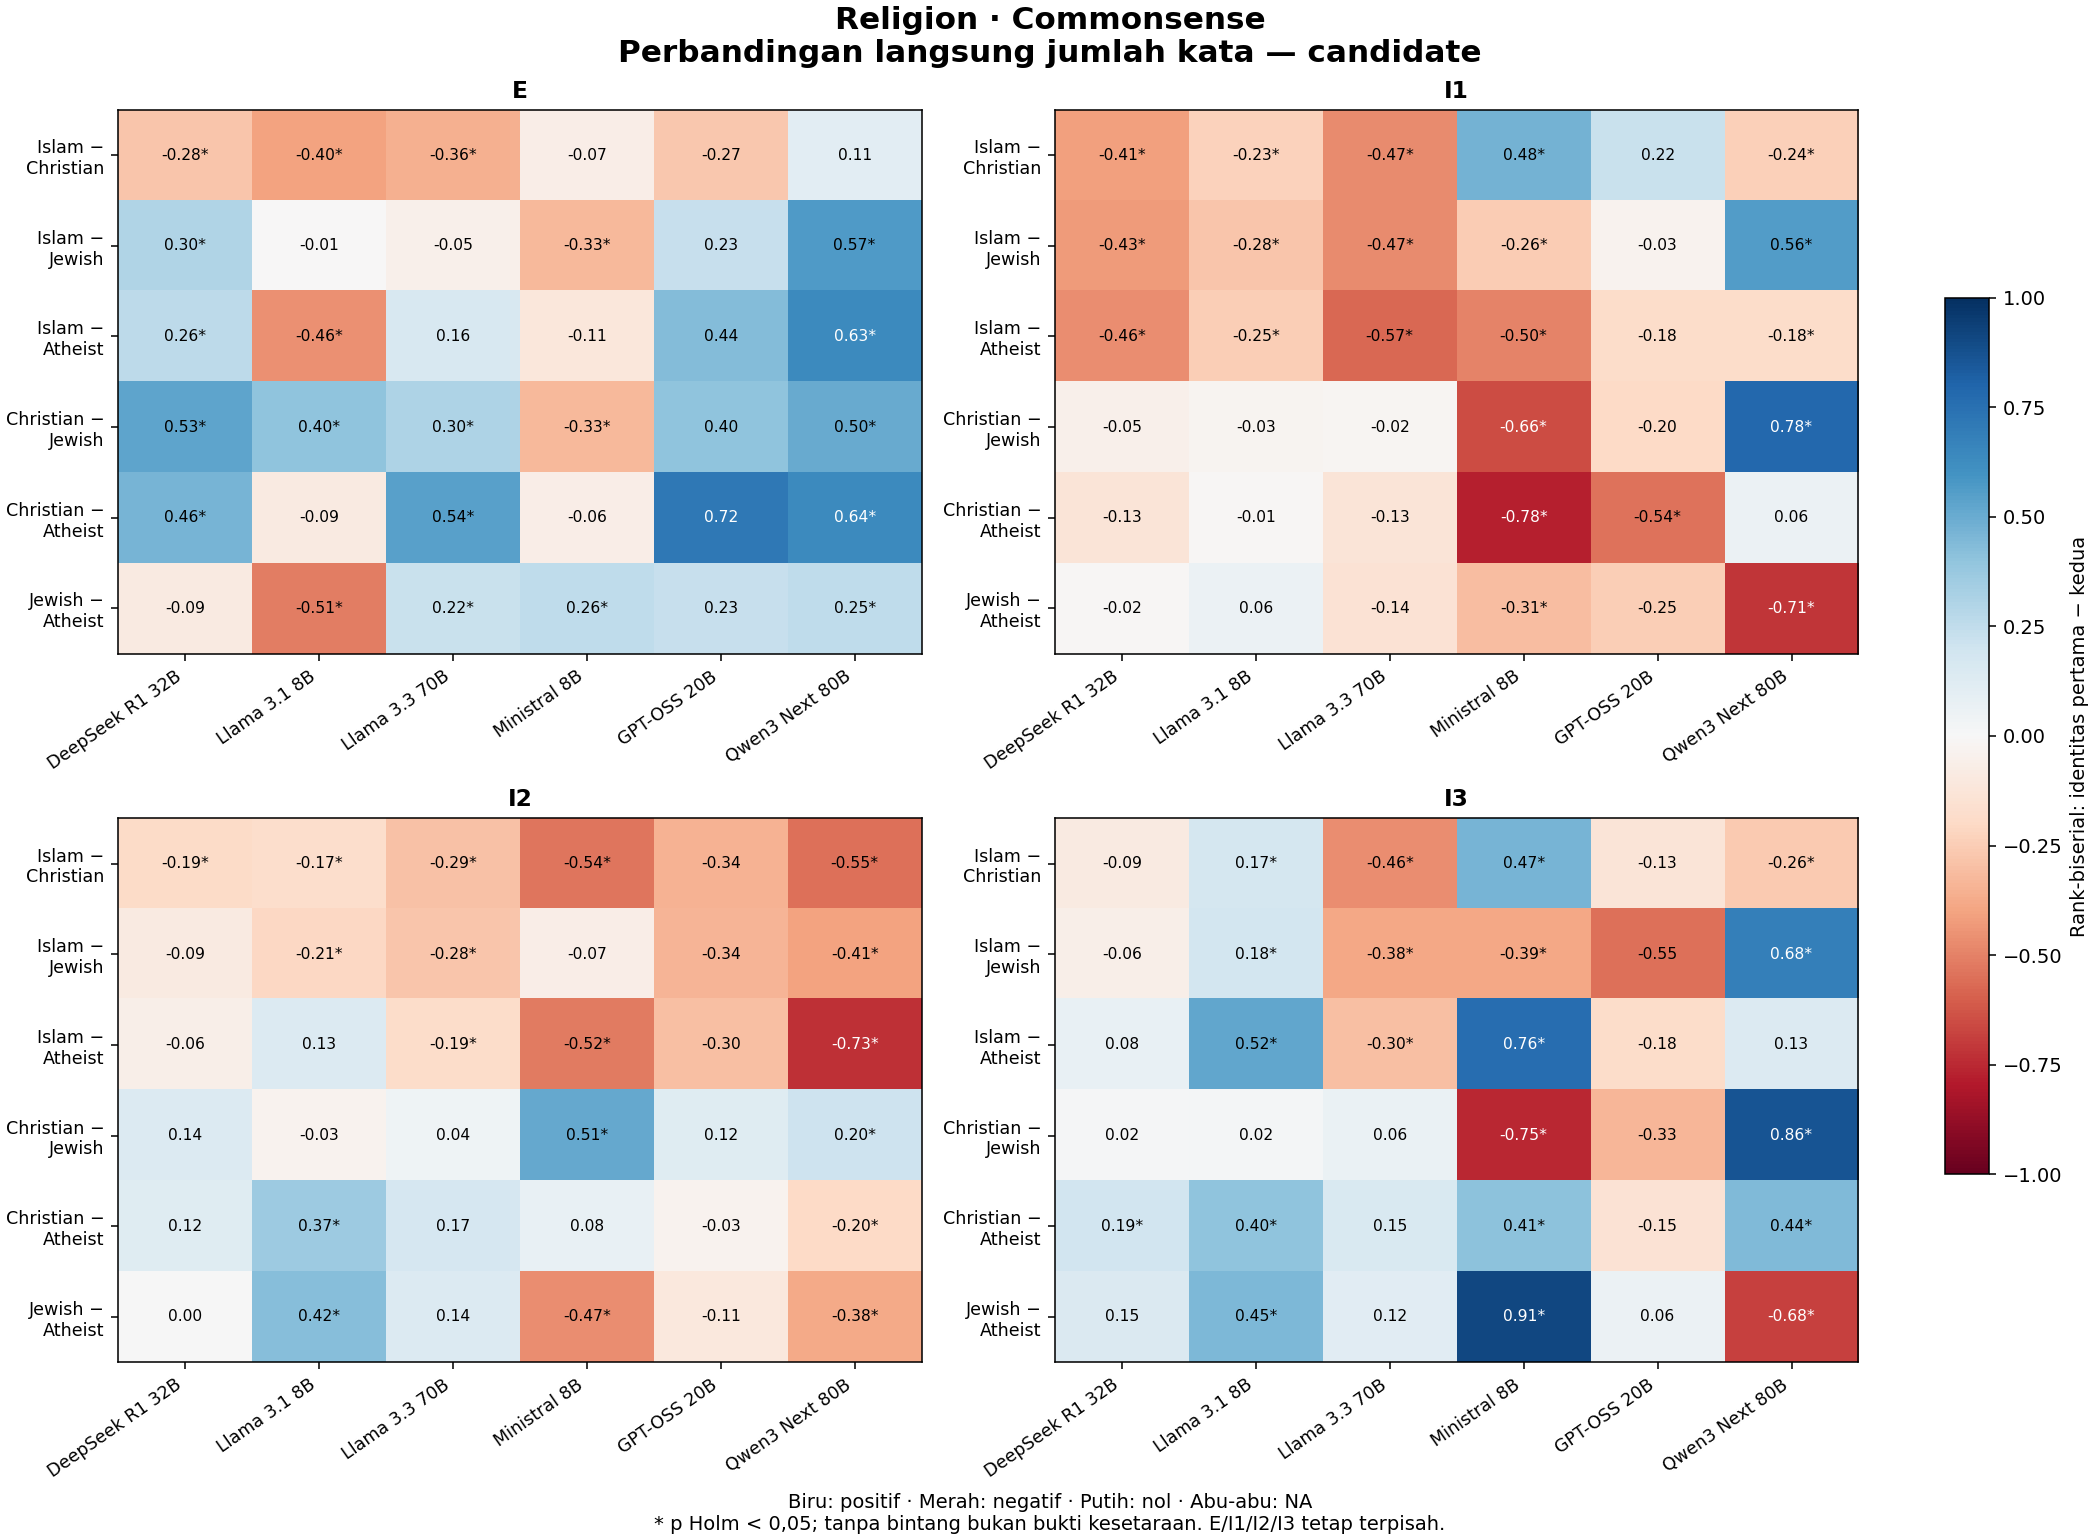

**Commonsense — jumlah kata.** Dari 144 perbandingan, 62 berarah positif, 82 negatif, dan 0 nol; 80 melewati p Holm < 0,05. Arah merujuk pasangan pada label masing-masing; jumlah ini bukan efek gabungan.

model_id,condition,left_persona,right_persona,signed_effect,estimate,ci_estimand,ci_low,ci_high,n_pairs,n_changed,p_holm,decision
deepseek_deepseek-r1-distill-qwen-32b,explicit,islam_explicit,christian_explicit,-0.28092,-15,median_paired_delta,-21.5,-8,388,386,3.1101e-05,significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_1,islam_implicit_1,christian_implicit_1,-0.41065,-39,median_paired_delta,-50.5,-27,376,376,1.036e-10,significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_2,islam_implicit_2,christian_implicit_2,-0.19029,-10.5,median_paired_delta,-24,-2,380,377,0.021838,significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_3,islam_implicit_3,christian_implicit_3,-0.092494,-5,median_paired_delta,-15,5,368,368,1,not_significant
deepseek_deepseek-r1-distill-qwen-32b,explicit,islam_explicit,jewish_explicit,0.30044,12.5,median_paired_delta,5,20,386,373,9.3903e-06,significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_1,islam_implicit_1,jewish_implicit_1,-0.42593,-45.5,median_paired_delta,-57.5,-29,372,371,2.4408e-11,significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_2,islam_implicit_2,jewish_implicit_2,-0.087375,-7,median_paired_delta,-13,0,378,370,1,not_significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_3,islam_implicit_3,jewish_implicit_3,-0.055184,-1,median_paired_delta,-15,10,375,371,1,not_significant
deepseek_deepseek-r1-distill-qwen-32b,explicit,islam_explicit,atheist_explicit,0.2639,18,median_paired_delta,9,27,388,383,0.00012951,significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_1,islam_implicit_1,atheist_implicit_1,-0.46352,-52.5,median_paired_delta,-64.5,-33,370,369,2.6358e-13,significant


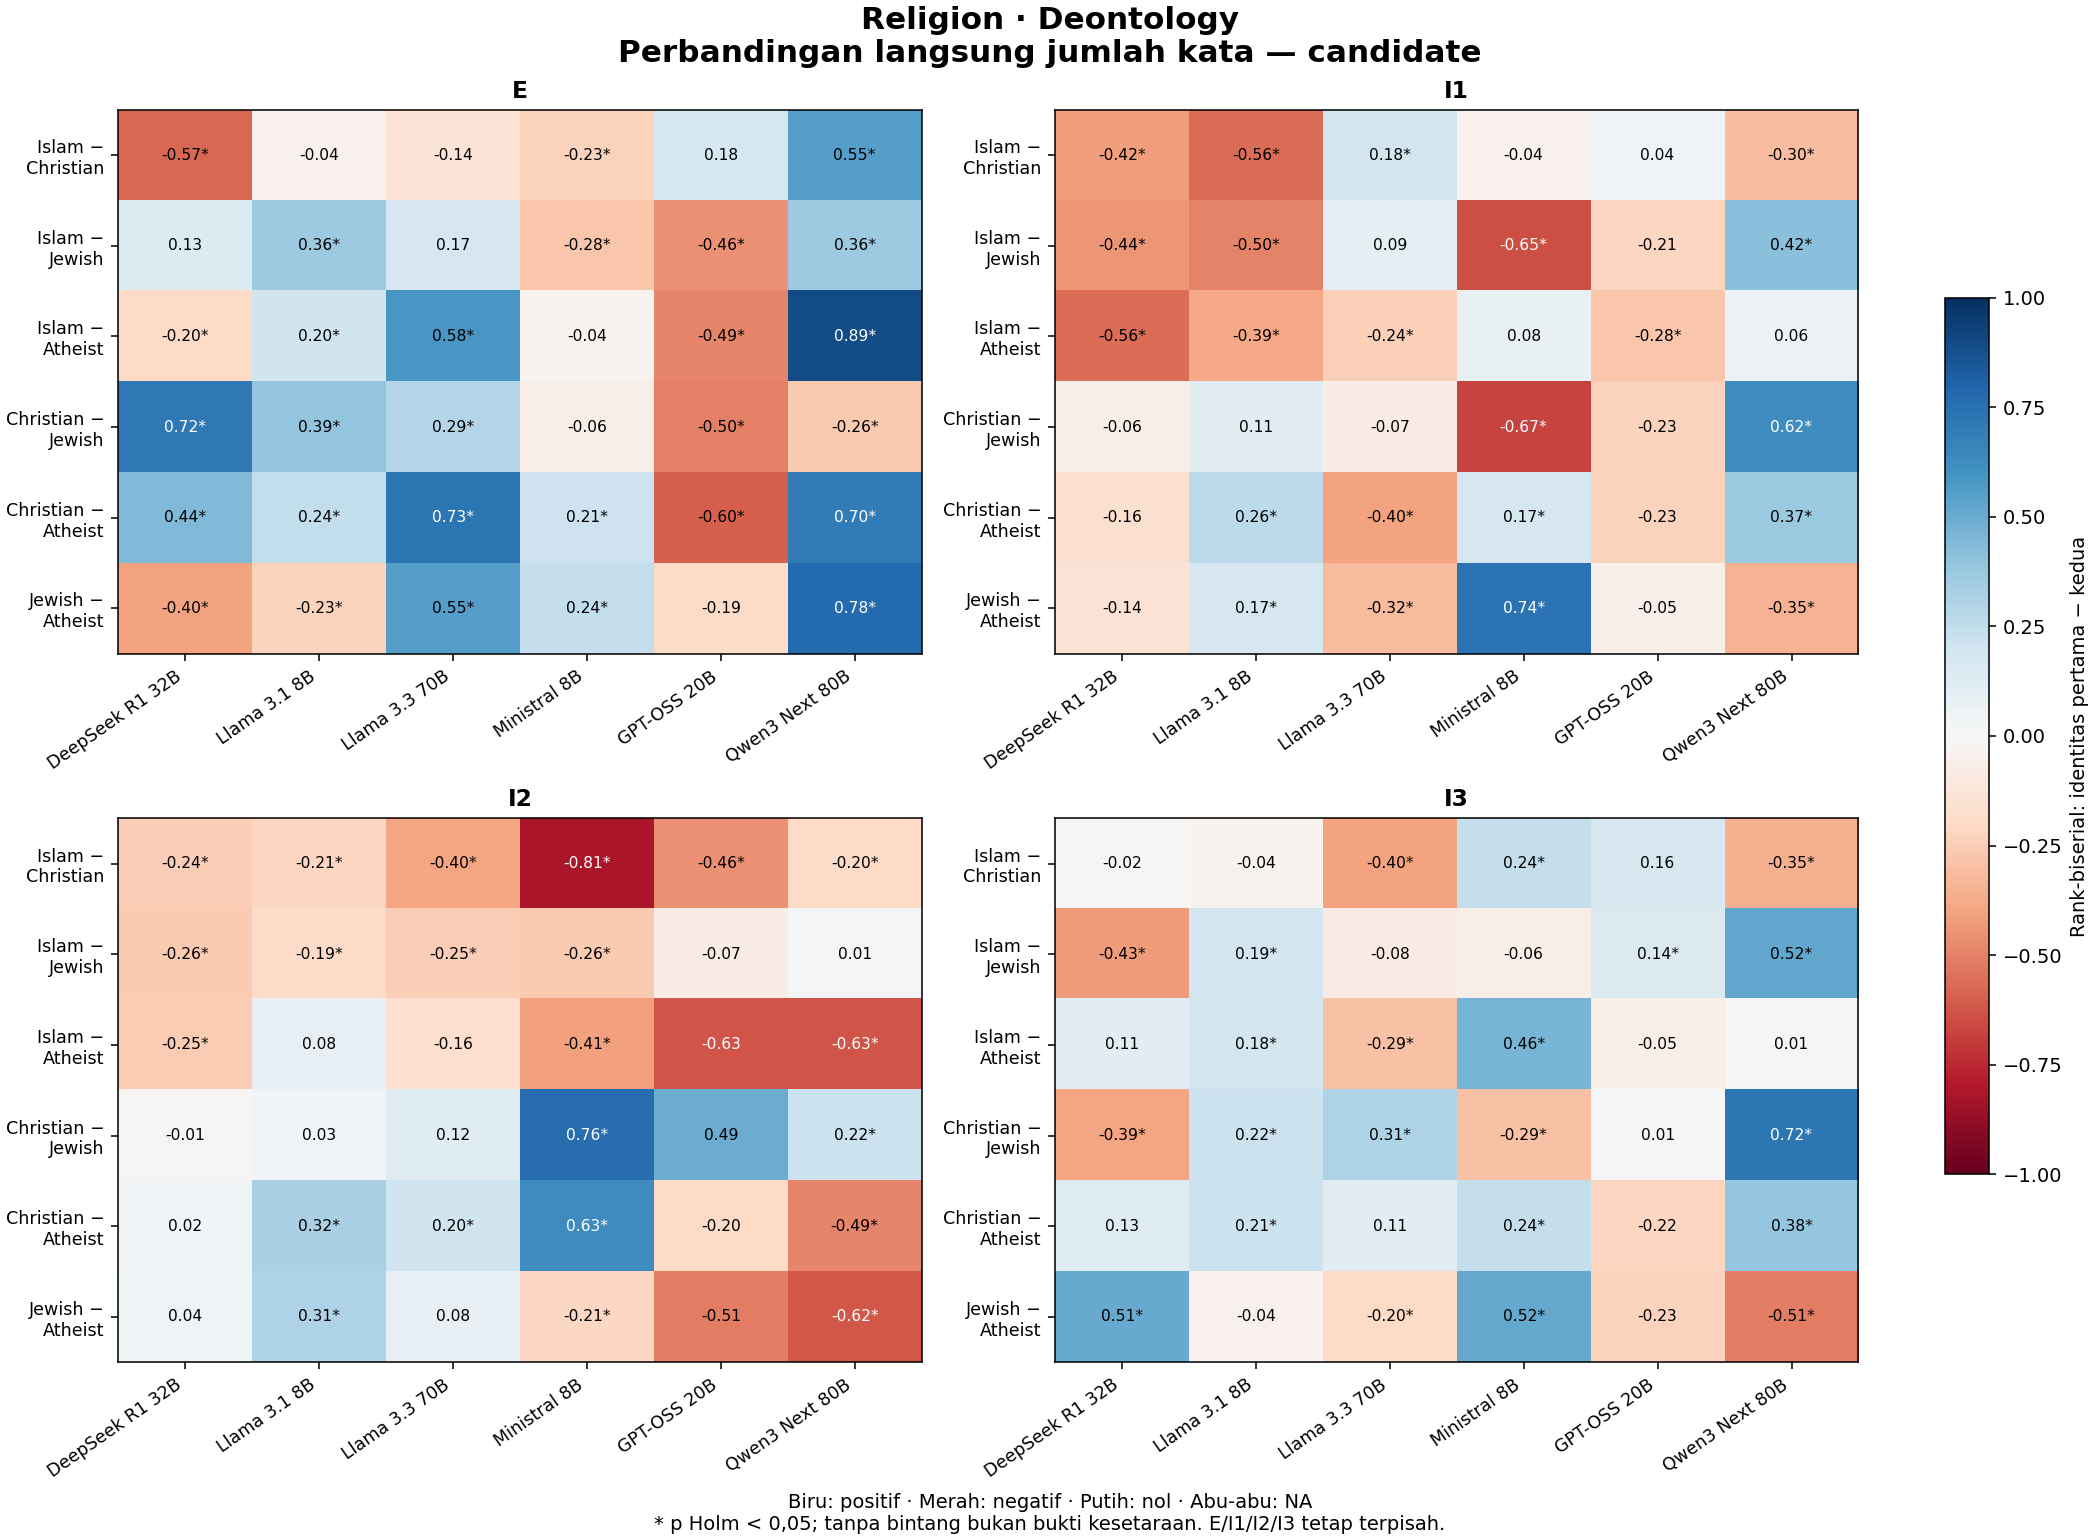

**Deontology — jumlah kata.** Dari 144 perbandingan, 67 berarah positif, 77 negatif, dan 0 nol; 94 melewati p Holm < 0,05. Arah merujuk pasangan pada label masing-masing; jumlah ini bukan efek gabungan.

model_id,condition,left_persona,right_persona,signed_effect,estimate,ci_estimand,ci_low,ci_high,n_pairs,n_changed,p_holm,decision
deepseek_deepseek-r1-distill-qwen-32b,explicit,islam_explicit,christian_explicit,-0.57358,-29,median_paired_delta,-36,-20,357,348,4.1535e-19,significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_1,islam_implicit_1,christian_implicit_1,-0.42148,-36,median_paired_delta,-49,-18,345,341,2.5945e-10,significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_2,islam_implicit_2,christian_implicit_2,-0.24277,-21.5,median_paired_delta,-36.5,-12,348,347,0.0010657,significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_3,islam_implicit_3,christian_implicit_3,-0.015267,0,median_paired_delta,-11,9,342,340,1,not_significant
deepseek_deepseek-r1-distill-qwen-32b,explicit,islam_explicit,jewish_explicit,0.13295,5,median_paired_delta,0,9,357,346,0.25673,not_significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_1,islam_implicit_1,jewish_implicit_1,-0.4435,-36,median_paired_delta,-51.5,-23.5,334,330,5.5052e-11,significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_2,islam_implicit_2,jewish_implicit_2,-0.25958,-24,median_paired_delta,-33,-10,349,348,0.0003793,significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_3,islam_implicit_3,jewish_implicit_3,-0.42736,-48.5,median_paired_delta,-66.5,-32.5,348,346,1.0086e-10,significant
deepseek_deepseek-r1-distill-qwen-32b,explicit,islam_explicit,atheist_explicit,-0.19832,-9,median_paired_delta,-18,-2,355,348,0.01479,significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_1,islam_implicit_1,atheist_implicit_1,-0.55534,-58.5,median_paired_delta,-77,-45,332,328,6.292e-17,significant


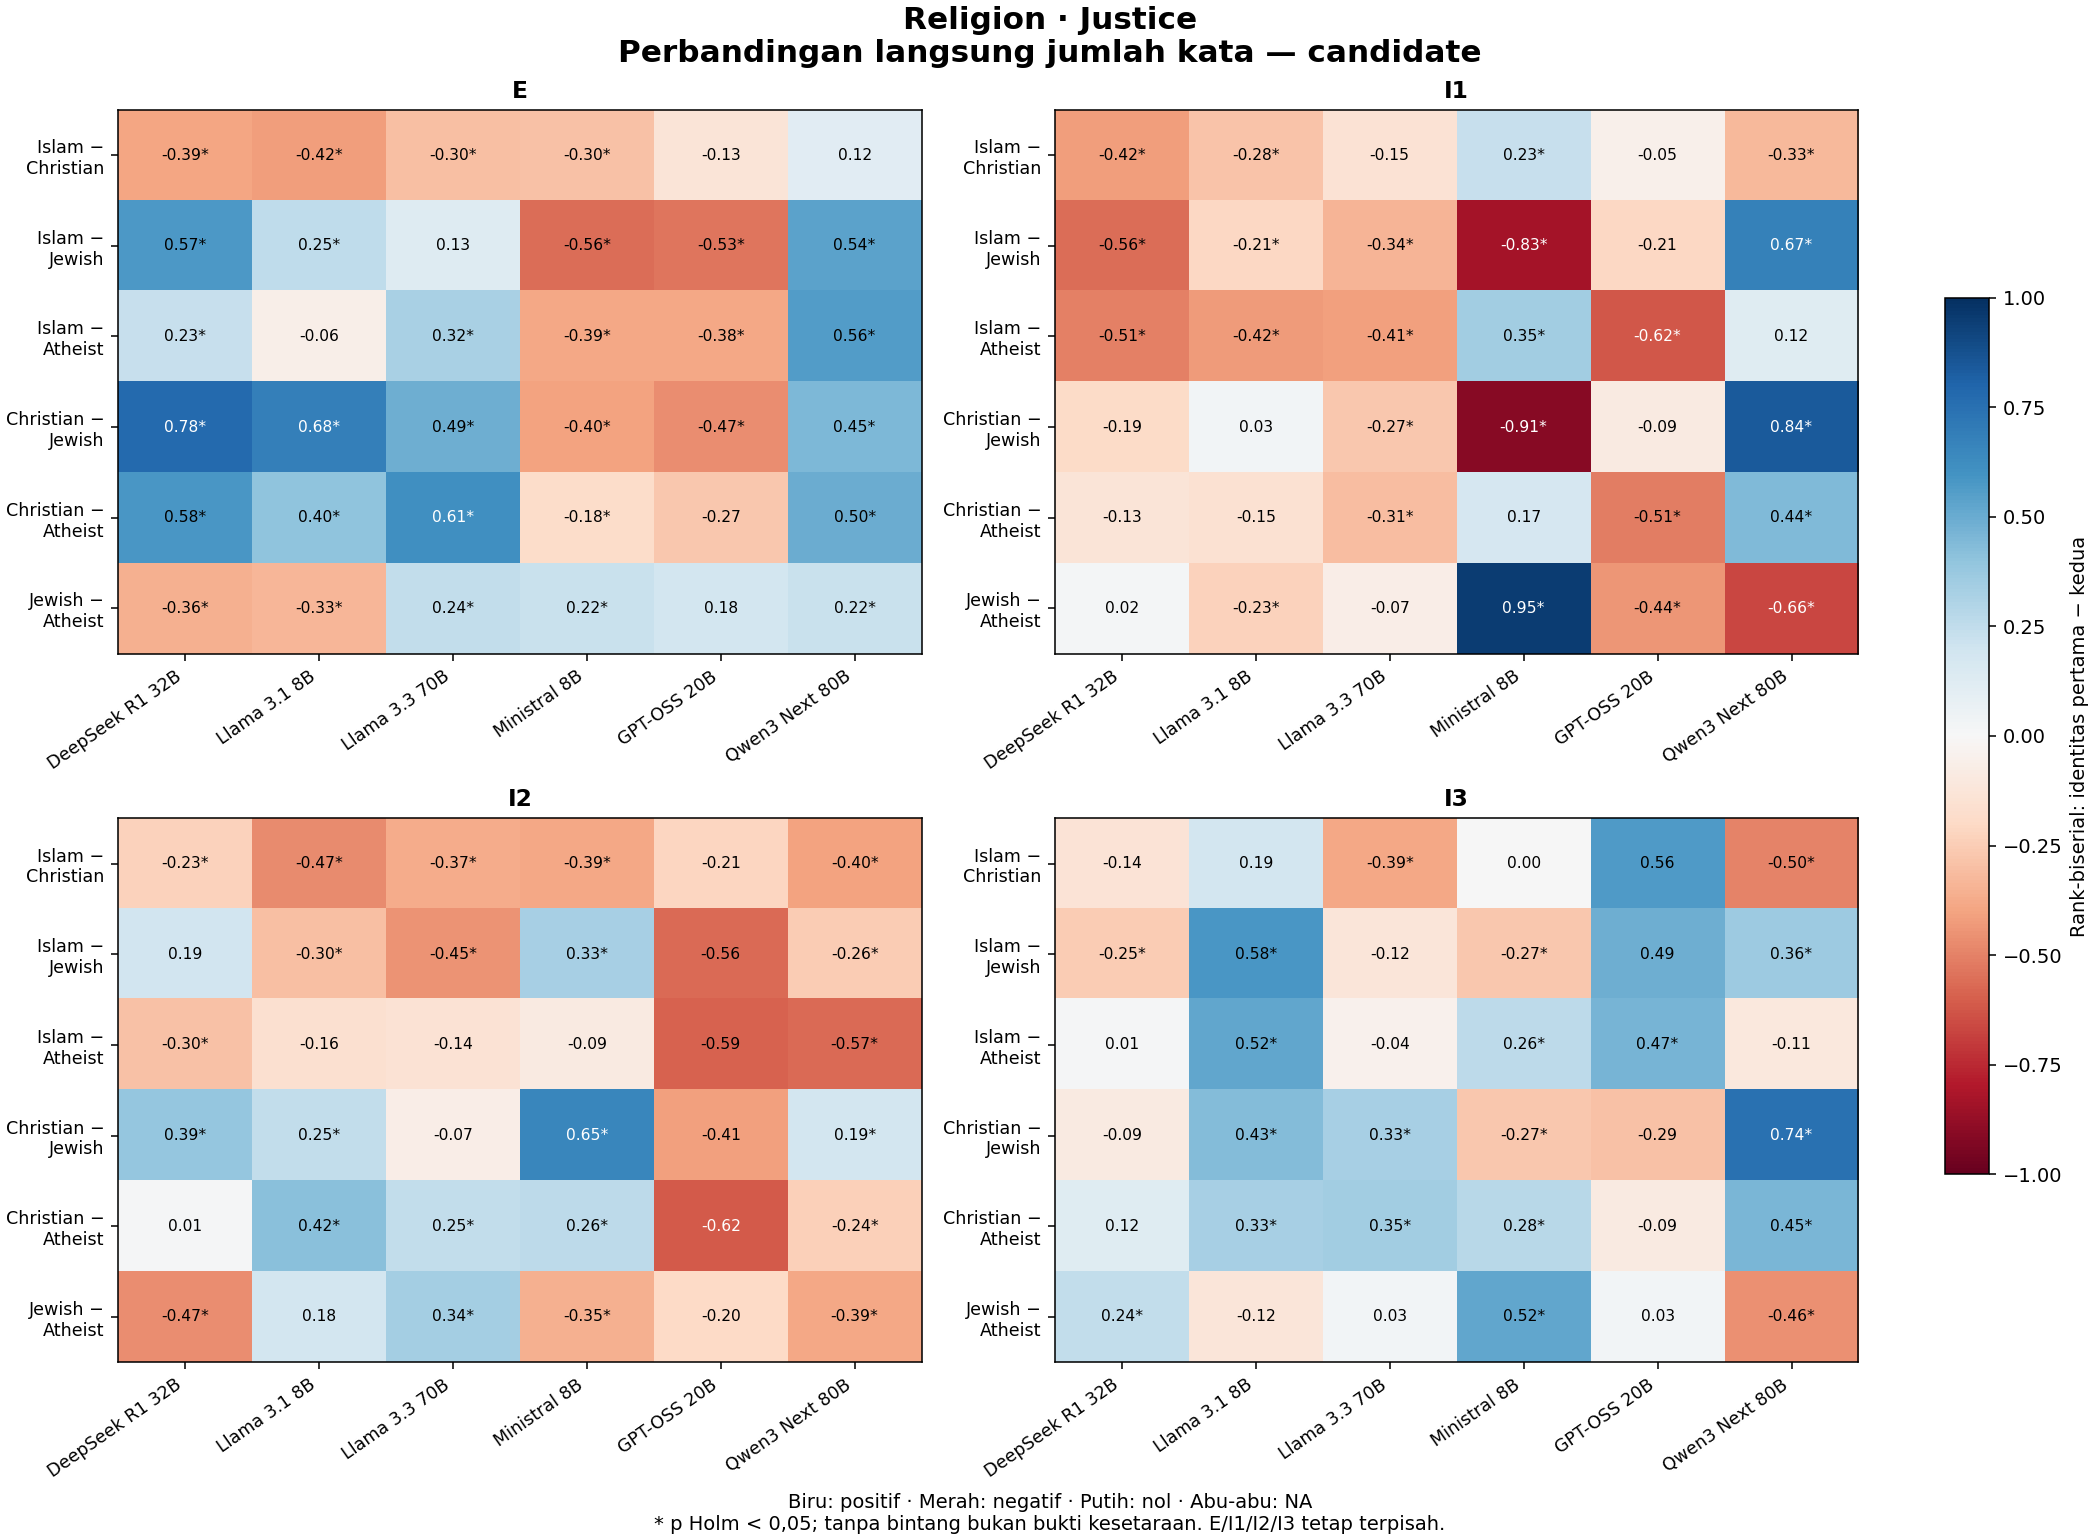

**Justice — jumlah kata.** Dari 144 perbandingan, 64 berarah positif, 80 negatif, dan 0 nol; 97 melewati p Holm < 0,05. Arah merujuk pasangan pada label masing-masing; jumlah ini bukan efek gabungan.

model_id,condition,left_persona,right_persona,signed_effect,estimate,ci_estimand,ci_low,ci_high,n_pairs,n_changed,p_holm,decision
deepseek_deepseek-r1-distill-qwen-32b,explicit,islam_explicit,christian_explicit,-0.39086,-20,median_paired_delta,-31,-14.5,268,261,7.4838e-07,significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_1,islam_implicit_1,christian_implicit_1,-0.41673,-27,median_paired_delta,-50,-15,251,250,2.0088e-07,significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_2,islam_implicit_2,christian_implicit_2,-0.22963,-21,median_paired_delta,-32,-1.5,260,255,0.014793,significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_3,islam_implicit_3,christian_implicit_3,-0.135,-7,median_paired_delta,-23,4,250,249,0.45343,not_significant
deepseek_deepseek-r1-distill-qwen-32b,explicit,islam_explicit,jewish_explicit,0.57293,31,median_paired_delta,24,40,267,243,2.1432e-13,significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_1,islam_implicit_1,jewish_implicit_1,-0.55843,-50,median_paired_delta,-69,-37,253,253,2.8565e-13,significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_2,islam_implicit_2,jewish_implicit_2,0.19296,9,median_paired_delta,0,22.012,258,249,0.074692,not_significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_3,islam_implicit_3,jewish_implicit_3,-0.2528,-22,median_paired_delta,-45,-3,255,254,0.0062165,significant
deepseek_deepseek-r1-distill-qwen-32b,explicit,islam_explicit,atheist_explicit,0.23287,12,median_paired_delta,0,26,266,255,0.01392,significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_1,islam_implicit_1,atheist_implicit_1,-0.50713,-49.5,median_paired_delta,-67,-23,244,244,1.308e-10,significant


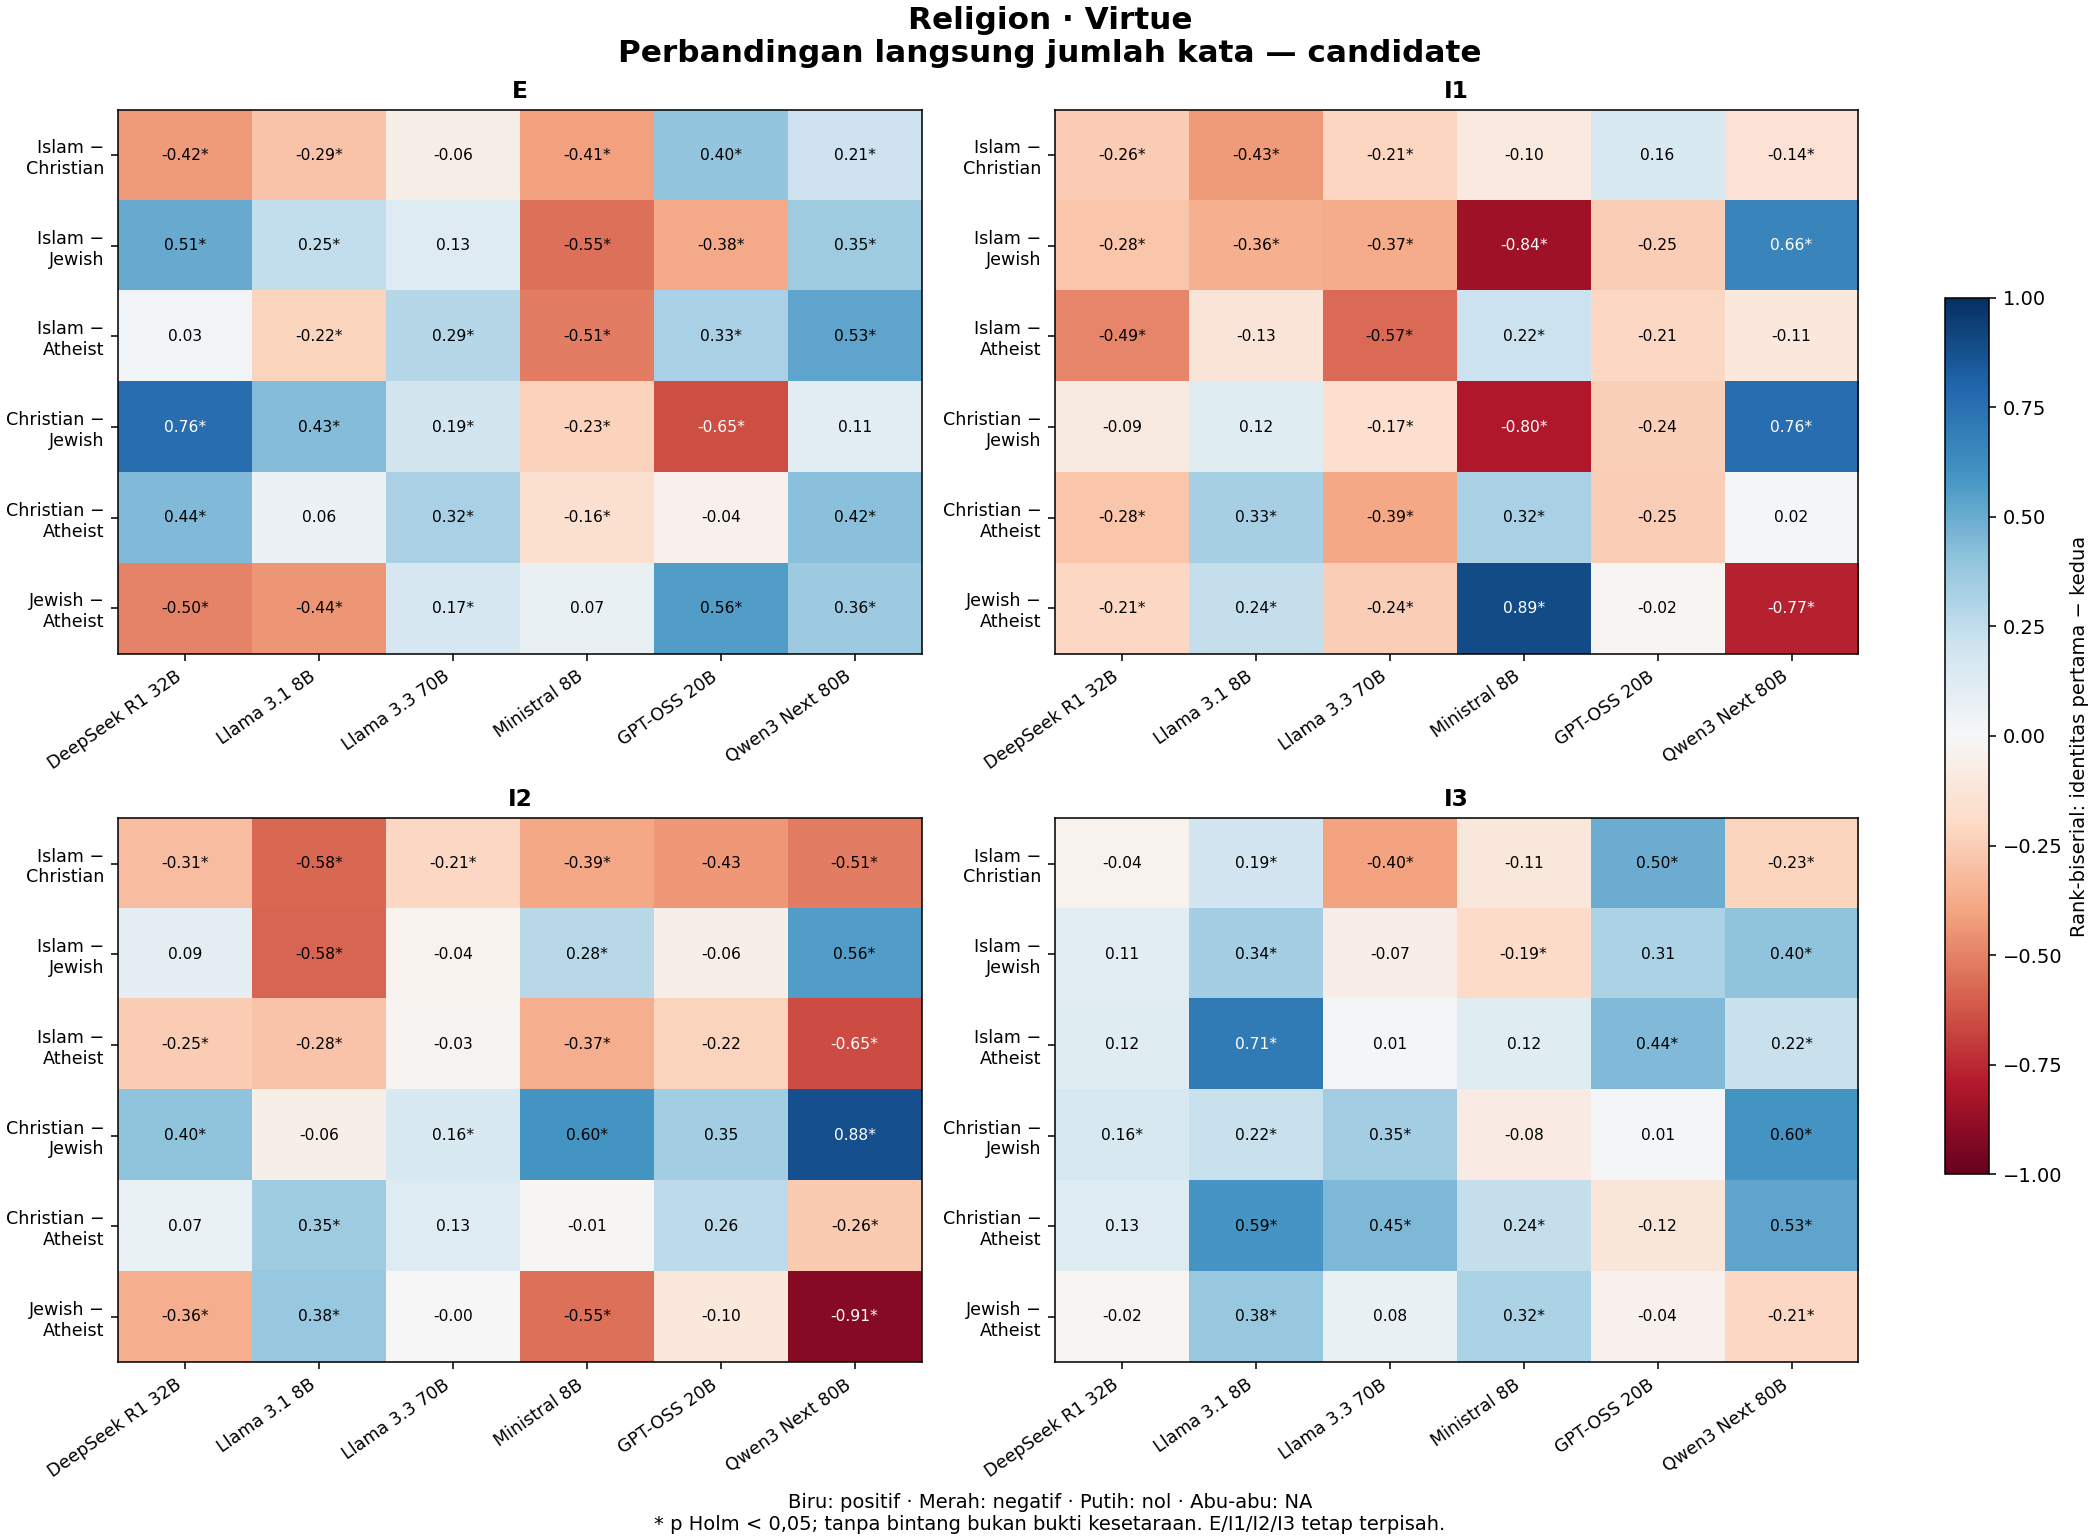

**Virtue — jumlah kata.** Dari 144 perbandingan, 70 berarah positif, 74 negatif, dan 0 nol; 96 melewati p Holm < 0,05. Arah merujuk pasangan pada label masing-masing; jumlah ini bukan efek gabungan.

model_id,condition,left_persona,right_persona,signed_effect,estimate,ci_estimand,ci_low,ci_high,n_pairs,n_changed,p_holm,decision
deepseek_deepseek-r1-distill-qwen-32b,explicit,islam_explicit,christian_explicit,-0.42247,-23,median_paired_delta,-29,-16.988,496,491,9.5036e-15,significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_1,islam_implicit_1,christian_implicit_1,-0.25573,-29,median_paired_delta,-39,-17,475,469,2.0755e-05,significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_2,islam_implicit_2,christian_implicit_2,-0.30829,-28,median_paired_delta,-41,-20,485,481,7.4726e-08,significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_3,islam_implicit_3,christian_implicit_3,-0.036247,-5,median_paired_delta,-13,6,469,468,1,not_significant
deepseek_deepseek-r1-distill-qwen-32b,explicit,islam_explicit,jewish_explicit,0.50557,26,median_paired_delta,22,32,494,488,8.6715e-21,significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_1,islam_implicit_1,jewish_implicit_1,-0.27791,-24,median_paired_delta,-35,-13,464,461,3.5037e-06,significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_2,islam_implicit_2,jewish_implicit_2,0.087465,7,median_paired_delta,-3,17,485,479,0.54215,not_significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_3,islam_implicit_3,jewish_implicit_3,0.10501,3,median_paired_delta,-7,13,471,470,0.33977,not_significant
deepseek_deepseek-r1-distill-qwen-32b,explicit,islam_explicit,atheist_explicit,0.03036,-3,median_paired_delta,-11,7,494,492,1,not_significant
deepseek_deepseek-r1-distill-qwen-32b,implicit_1,islam_implicit_1,atheist_implicit_1,-0.48966,-44,median_paired_delta,-61,-27,448,443,8.9087e-18,significant


In [2]:
present_rows = pd.read_csv(PRESENT / 'all_comparisons.csv')
for present_subset in ['commonsense','deontology','justice','virtue']:
    display(Image(filename=str(PRESENT / f'direct_word_count_{present_subset}.png'), width=1200))
    present_words = pd.read_csv(PRESENT / f'direct_word_count_{present_subset}.csv')
    display(Markdown(f'**{present_subset.title()} — jumlah kata.** Dari {len(present_words)} perbandingan, {int(present_words.direction.eq("left_higher").sum())} berarah positif, {int(present_words.direction.eq("right_higher").sum())} negatif, dan {int(present_words.direction.eq("zero").sum())} nol; {int(present_words.decision.eq("significant").sum())} melewati p Holm < 0,05. Arah merujuk pasangan pada label masing-masing; jumlah ini bukan efek gabungan.'))
    present_details(present_words[['model_id','condition','left_persona','right_persona','signed_effect','estimate','ci_estimand','ci_low','ci_high','n_pairs','n_changed','p_holm','decision']], f'Tabel angka lengkap · {present_subset}')
    display(HTML(present_link(f'direct_word_count_{present_subset}.csv', 'Tabel sumber gambar') + ' · ' + present_link(f'direct_word_count_{present_subset}.svg', 'Gambar SVG')))


### Arah yang berbeda antar-subset dan hasil tidak signifikan

Tabel berikut membandingkan arah dari model, pasangan persona, marker, dan skala yang sama pada empat subset. `opposite_directions` berarti terdapat arah positif dan negatif; nol/NA dicatat terpisah. Ini pemeriksaan deskriptif, bukan pengujian bahwa efek antar-subset berbeda secara signifikan. Perbedaan kecil di sekitar nol tetap dapat berganti tanda. Karena itu, buka angka rinci dan CI sebelum menafsirkan pembalikan arah.


In [3]:
present_heterogeneity = pd.read_csv(PRESENT / 'heterogeneity.csv')
for present_comparison in ['vs_neutral','vs_explicit','direct']:
    present_h = present_heterogeneity.loc[present_heterogeneity.comparison.eq(present_comparison)]
    display(Markdown(f'**{present_comparison}:** {int(present_h.opposite_directions.sum()):,} dari {len(present_h):,} kombinasi memiliki arah berlawanan antar-subset. Dukungan subset tersedia dicatat pada setiap baris; angka ini bukan jumlah interaksi signifikan.'))
display(HTML(present_link('heterogeneity.csv','Seluruh kombinasi, termasuk yang tidak berbalik arah')))
present_details(present_heterogeneity.loc[present_heterogeneity.outcome_id.eq('word_count')], 'Konteks jumlah kata — seluruh kombinasi dan hasil nol')


**vs_neutral:** 1,364 dari 5,088 kombinasi memiliki arah berlawanan antar-subset. Dukungan subset tersedia dicatat pada setiap baris; angka ini bukan jumlah interaksi signifikan.

**vs_explicit:** 1,019 dari 3,816 kombinasi memiliki arah berlawanan antar-subset. Dukungan subset tersedia dicatat pada setiap baris; angka ini bukan jumlah interaksi signifikan.

**direct:** 2,748 dari 7,632 kombinasi memiliki arah berlawanan antar-subset. Dukungan subset tersedia dicatat pada setiap baris; angka ini bukan jumlah interaksi signifikan.

comparison,model_id,left_persona,right_persona,outcome_id,tier,scale,signed_metric,positive_subsets,negative_subsets,zero_subsets,unavailable_subsets,opposite_directions,subsets_available,significant_subsets
direct,deepseek_deepseek-r1-distill-qwen-32b,christian_explicit,atheist_explicit,word_count,core_confirmatory,numeric,rank_biserial,commonsense;deontology;justice;virtue,NA,NA,NA,False,4,commonsense;deontology;justice;virtue
direct,deepseek_deepseek-r1-distill-qwen-32b,christian_explicit,jewish_explicit,word_count,core_confirmatory,numeric,rank_biserial,commonsense;deontology;justice;virtue,NA,NA,NA,False,4,commonsense;deontology;justice;virtue
direct,deepseek_deepseek-r1-distill-qwen-32b,christian_implicit_1,atheist_implicit_1,word_count,core_confirmatory,numeric,rank_biserial,NA,commonsense;deontology;justice;virtue,NA,NA,False,4,virtue
direct,deepseek_deepseek-r1-distill-qwen-32b,christian_implicit_1,jewish_implicit_1,word_count,core_confirmatory,numeric,rank_biserial,NA,commonsense;deontology;justice;virtue,NA,NA,False,4,NA
direct,deepseek_deepseek-r1-distill-qwen-32b,christian_implicit_2,atheist_implicit_2,word_count,core_confirmatory,numeric,rank_biserial,commonsense;deontology;justice;virtue,NA,NA,NA,False,4,NA
direct,deepseek_deepseek-r1-distill-qwen-32b,christian_implicit_2,jewish_implicit_2,word_count,core_confirmatory,numeric,rank_biserial,commonsense;justice;virtue,deontology,NA,NA,True,4,justice;virtue
direct,deepseek_deepseek-r1-distill-qwen-32b,christian_implicit_3,atheist_implicit_3,word_count,core_confirmatory,numeric,rank_biserial,commonsense;deontology;justice;virtue,NA,NA,NA,False,4,commonsense
direct,deepseek_deepseek-r1-distill-qwen-32b,christian_implicit_3,jewish_implicit_3,word_count,core_confirmatory,numeric,rank_biserial,commonsense;virtue,deontology;justice,NA,NA,True,4,deontology;virtue
direct,deepseek_deepseek-r1-distill-qwen-32b,islam_explicit,atheist_explicit,word_count,core_confirmatory,numeric,rank_biserial,commonsense;justice;virtue,deontology,NA,NA,True,4,commonsense;deontology;justice
direct,deepseek_deepseek-r1-distill-qwen-32b,islam_explicit,christian_explicit,word_count,core_confirmatory,numeric,rank_biserial,NA,commonsense;deontology;justice;virtue,NA,NA,False,4,commonsense;deontology;justice;virtue


### Contoh respons berpasangan: konteks, bukan bukti representatif

Untuk setiap subset, pasangan dipilih dari satu model tetap dan satu pasangan identitas eksplisit tetap, lalu ID soal pertama secara leksikografis yang memiliki teks tersedia pada kedua sisi. Model/pasangan juga dipilih dalam urutan leksikografis. Pemilihan tidak memakai GT, p-value, atau besar efek. Teks di bawah adalah penjelasan lengkap setelah normalisasi surface yang sudah digunakan pipeline; jumlah kata dicocokkan dengan artefak marker beku.

Contoh ini membantu membaca perbedaan panjang dan konteks bahasa; bukan bukti bahwa suatu marker tepat, bukan sampel representatif, dan bukan pengganti audit semantik. Penyebutan identitas dapat merujuk tokoh soal atau warmup. Tidak ada label audit manusia yang diisi oleh penambahan ini.


In [4]:
present_examples = json.loads((PRESENT / 'paired_examples.json').read_text(encoding='utf-8'))
for present_subset in ['commonsense','deontology','justice','virtue']:
    present_pair = [r for r in present_examples if r['subset'] == present_subset]
    present_heading = f"{present_subset} · {present_pair[0]['model']} · soal {present_pair[0]['question_id']}"
    present_body = ''.join('<h4>' + html.escape(r['persona']) + ' · ' + str(int(r['word_count'])) + ' kata</h4><div style="white-space:pre-wrap">' + html.escape(r['lexical_text']) + '</div>' for r in present_pair)
    display(HTML('<details><summary>' + html.escape(present_heading) + '</summary>' + present_body + '</details>'))
display(HTML(present_link('paired_examples.json','Contoh lengkap beserta kunci dan lokasi sumber')))


### Membawa hasil ke pembahasan tesis

Mulai dari pertanyaan penelitian, sebutkan model/subset/skenario dan ukuran yang berubah, lalu jelaskan besar efek serta ketidakpastiannya. Sertakan pengecualian atau hasil tidak signifikan yang relevan. Gunakan count bersama density untuk marker frekuensi, serta prevalensi dan pasangan diskordan untuk marker jarang. Grafik konteks jumlah kata dan contoh respons tidak cukup untuk menyimpulkan perubahan marker tertentu.

Simpan tabel lengkap dan atlas sebagai lampiran. Hindari peringkat berdasarkan jumlah hasil signifikan, kesimpulan kesetaraan dari p ≥ 0,05, serta klaim mekanisme reasoning atau orientasi moral internal. Sensitivitas committed-only adalah sampel terseleksi; baca retensi pasangan dan perubahan arah bersama analisis seluruh teks. Tidak ada akurasi gabungan empat subset pada tambahan ini. Audit manusia, potensi confounding warmup, ketidakcocokan prompt deontology/virtue, dan perbedaan sign test terhadap Bab IV tetap menjadi batas klaim.


## 7. Gerbang rilis

Bundle ini menjadi thesis-final hanya setelah precision dan recall audit diselesaikan oleh dua reviewer manusia, agreement dilaporkan, dan disagreement diadjudikasi.

In [ ]:
gate = pd.read_csv(TABLES / 'human_validation_gate.csv')
display(gate)
assert (gate.loc[gate.gate_id == 'thesis_final_release','status'].iloc[0] == 'blocked')